# Which water quality products survive with TRISHNA bands?

## Requirements
- A GRS L2A Sentinel-2 product.

## Tutorial objectives
- List the water quality algorithms that TRISHNA bands can feed.
- Compute the products from a Sentinel-2 image with all bands and with TRISHNA-like bands.
- Quantify the impact of the band differences (adjustment factors, OWT-dependent) and of the TRISHNA noise.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 1 core, 4 GB. Run time: ~2 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
plt.rcParams.update({'figure.dpi': 90, 'font.size': 11})

from trishna_tbx import algorithms, owt

trishna_tbx 0.0.1


## Data
> **Data paths.** On the CNES JupyterHub, point the variables below to the TREX datalake or to your project space. Outside CNES, download Sentinel-2 L1C with the *Access data - Copernicus API* tutorial. Each path can also be set through the environment variable named in the cell.

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
S2_L1C = os.environ.get('TRISHNA_TBX_S2_L1C',
    '/data/satellite/Sentinel-2/L1C/31TFJ/2025/05/26/'
    'S2B_MSIL1C_20250526T103629_N0511_R008_T31TFJ_20250526T123708.SAFE')
CAMS_FILE = os.environ.get('TRISHNA_TBX_CAMS', '/data/cams/world/cams_forecast_2025-05.nc')
# 30 km box (UTM 31N) over the Berre lagoon and the eastern Gulf of Fos
SUBSET = [(655000, 4800000, 685000, 4830000)]
L2A_DIR = os.environ.get('TRISHNA_TBX_L2A_DIR',
    '/home/harmel/Dropbox/Dropbox/work/projet/unesco/satellite/L2A')  # GRS L2A (beam profile)
L2A_TILE = 'T33PVQ'                      # Lake Chad (southern pool)
L2A_WINDOW = 'y=0:3600,x=0:960'          # 20 m pixel window with water
L2A_DATE = '2022-02-12'                  # date used by the single-image tutorials
# single-image example of the products tutorial: Loire estuary and plume, GRS v3.1.1 (Zarr pyramid,
# local S3 bucket grstbx-s3 of grstbx, read here through its folder)
L2A_EXAMPLE = os.environ.get('TRISHNA_TBX_L2A_EXAMPLE',
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2a/30TWT/2017/04/12/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
L2A_EXAMPLE_WINDOW = 'y=2700:5490,x=1500:4500'   # 20 m pixels: estuary, plume, Bourgneuf Bay
AERONET_HYP_DIR = os.environ.get('TRISHNA_TBX_AERONET_HYP', '/DATA/AERONET/OCv3_invRrs/data')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Algorithm coverage
Each algorithm declares the wavelengths it needs; a sensor covers it if it has a band within
15 nm of each. This avoids the silent "nearest band" substitution (443 -> 485 nm,
705 -> 670 nm) of generic codes.

In [3]:
s2 = make_s2()
cov = algorithms.coverage([s2, TRISHNA])
cov.style.map(lambda v: 'background-color: #c8e6c9' if v is True else
              ('background-color: #ffcdd2' if v is False else ''))

## 2. Products from a Sentinel-2 image
Example: the Loire estuary and plume (tile T30TWT, 2017-04-12), from clear coastal waters to the
very turbid estuary. The GRS L2A product is a Zarr pyramid: level 0 is the 20 m grid.

In [4]:
from trishna_tbx.io import open_grs_l2a, water_mask, to_60m
ds = open_grs_l2a(L2A_EXAMPLE, L2A_EXAMPLE_WINDOW, level=0)
date = ds.time.values
rrs = to_60m(ds.Rrs.where(water_mask(ds))).load()
rrs = rrs.where((rrs.sel(wl=[490, 560, 665]) > 0).all('wl'))
print(str(date)[:10], L2A_EXAMPLE.split('/')[-1], '| 60 m water pixels:', int(rrs.sel(wl=560).notnull().sum()))

2017-04-12 S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr | 60 m water pixels: 486746


In [5]:
S2T = s2.subset(['B2', 'B3', 'B4', 'B8A'], 'S2-as-TRISHNA')
prod_s2 = algorithms.run_all(rrs, s2)
rrs_t = rrs.sel(wl=[490, 560, 665, 865])
prod_t = algorithms.run_all(rrs_t, S2T)
print('S2 only :', sorted(set(prod_s2) - set(prod_t)))
print('both    :', sorted(prod_t))

S2 only : ['Chla_index_NDCI']
both    : ['Chla_OC2', 'Kd490_KD2', 'Kd_par_RD22', 'OWT_index_NDI', 'SPM_Nechad10', 'SPM_index_RedNIR', 'TUR_Dogliotti15']


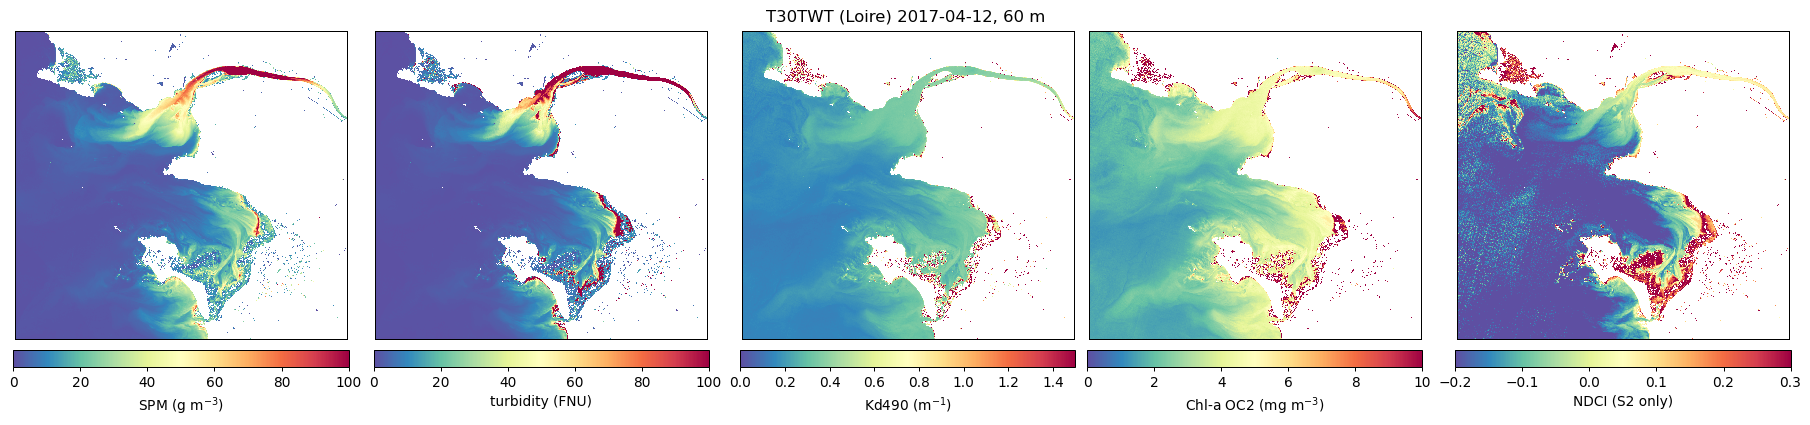

In [6]:
show = [('SPM_Nechad10', 'SPM (g m$^{-3}$)', 0, 100), ('TUR_Dogliotti15', 'turbidity (FNU)', 0, 100),
        ('Kd490_KD2', 'Kd490 (m$^{-1}$)', 0, 1.5), ('Chla_OC2', 'Chl-a OC2 (mg m$^{-3}$)', 0, 10),
        ('Chla_index_NDCI', 'NDCI (S2 only)', -0.2, 0.3)]
fig, axs = plt.subplots(1, 5, figsize=(20, 4.6), sharey=True, layout='constrained')
for ax, (v, lab, lo, hi) in zip(axs, show):
    src = prod_t if v in prod_t else prod_s2
    im = ax.imshow(src[v], vmin=lo, vmax=hi, cmap='Spectral_r', interpolation='nearest')
    fig.colorbar(im, ax=ax, orientation='horizontal', pad=.03, label=lab)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'T30TWT (Loire) {str(date)[:10]}, 60 m')
fig.savefig(THUMB_DIR / 'wq_products_trishna.png', dpi=60)

OC2 is designed for clear waters: in the turbid plume and estuary its values are not meaningful
(it is shown because it is the only Chl-a algorithm left with TRISHNA bands). The red-edge NDCI,
sensitive to Chl-a in turbid/productive waters, is lost.

## 3. From "S2 restricted to TRISHNA bands" to TRISHNA
On the same S2 values, covered algorithms give identical products. Two effects make TRISHNA
different: (1) the band responses (adjustment factors, which depend on the water type),
(2) the radiometric noise.

In [7]:
from trishna_tbx.emulate import owt_band_adjustment
# OWT of each pixel (TRISHNA-like bands), then OWT-dependent S2 -> TRISHNA factors
rrs_tri, cls, factors = owt_band_adjustment(rrs_t, S2T)
factors.round(3)

,490,560,665,865
all types,0.927,0.973,0.998,1.056
1,1.280,1.095,0.972,1.056
2,1.165,1.068,0.971,1.056
3a,1.009,1.002,0.974,1.059
3b,0.985,1.004,0.983,1.066
4a,0.929,0.966,0.987,1.053
4b,0.902,0.970,1.003,1.060
5a,0.856,0.939,1.077,1.064
5b,0.836,0.949,1.165,1.039
6,0.922,0.973,1.003,1.023


In [8]:
prod_tri = algorithms.run_all(rrs_tri, S2T)

# TRISHNA noise (requirement SNR, TOA -> Rrs)
sig = (TRISHNA.subset(['Blue', 'Green', 'Red', 'NIR']).noise_reflectance(30.) / (np.pi * 0.75))
sig = xr.DataArray(sig.values, dims='wl', coords={'wl': rrs_t.wl})
rng = np.random.default_rng(0)
rrs_noisy = rrs_tri + sig * xr.DataArray(rng.standard_normal(rrs_tri.shape), dims=rrs_tri.dims)
prod_noisy = algorithms.run_all(rrs_noisy, S2T)

rows = {}
for v in prod_t:
    a, b, c = prod_t[v], prod_tri[v], prod_noisy[v]
    rel = lambda u: 100 * np.nanmedian(np.abs(u - a) / np.abs(a))
    rows[v] = {'median S2': float(a.median()), 'band adjustment: MdAPD (%)': rel(b),
               '+ noise: MdAPD (%)': rel(c)}
pd.DataFrame(rows).T.round(2)

,median S2,band adjustment: MdAPD (%),+ noise: MdAPD (%)
Chla_OC2,2.16,4.27,13.25
SPM_Nechad10,3.28,1.79,5.27
TUR_Dogliotti15,2.11,1.80,5.98
SPM_index_RedNIR,0.25,8.46,35.25
Kd490_KD2,0.19,3.62,11.05
Kd_par_RD22,1.84,1.69,6.25
OWT_index_NDI,0.57,1.52,4.40


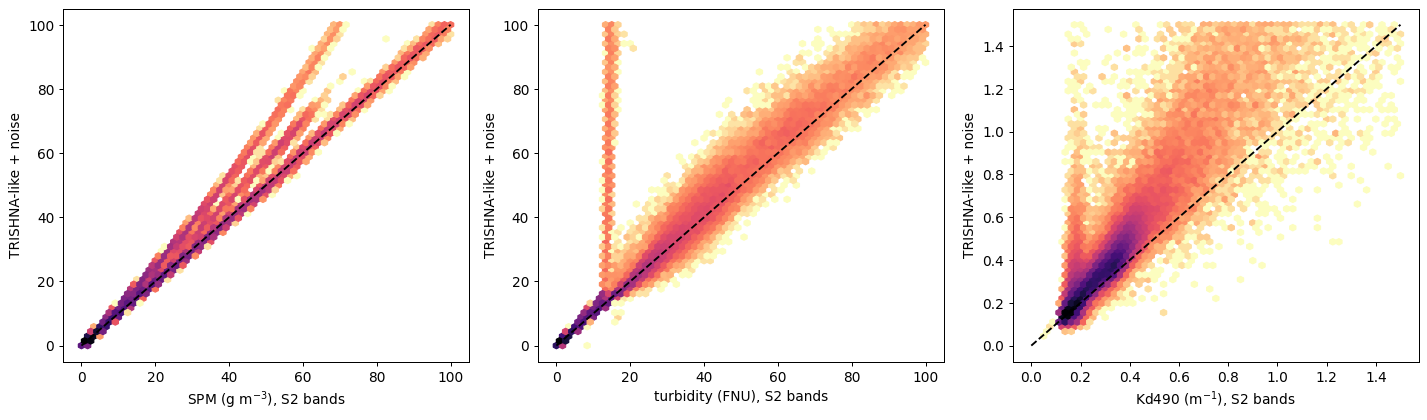

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (v, lab, lo, hi) in zip(axs, show[:3]):
    a, c = prod_t[v].values.ravel(), prod_noisy[v].values.ravel()
    ok = np.isfinite(a) & np.isfinite(c)
    ax.hexbin(a[ok], c[ok], gridsize=60, bins='log', extent=(lo, hi, lo, hi), cmap='magma_r')
    ax.plot([lo, hi], [lo, hi], 'k--'); ax.set_xlabel(f'{lab}, S2 bands'); ax.set_ylabel('TRISHNA-like + noise')
fig.tight_layout()

## Take-home messages
- Retrievable with TRISHNA bands: SPM / turbidity (red, NIR), diffuse attenuation (Kd490,
  Kd_PAR), OWT, and blue/green Chl-a in clear waters only.
- Lost: red-edge Chl-a (productive/eutrophic waters), CDOM, QAA-based IOPs and Secchi depth
  as implemented (443 nm); a QAA variant using 485 nm has to be developed.
- The effect of the band differences depends on the water type. On this coastal image (Loire
  plume, mostly moderately turbid), the OWT-dependent adjustment changes the products by only
  2-4 % (8 % for the red/NIR index). It is larger in very turbid waters (OWT 5b), where TRISHNA
  Red (670/60 nm, wider and redder than S2 B4) sees up to ~15 % more signal, and on the Lake Chad
  time series (*Time series of TRISHNA-like water products*: SPM +7 to +16 %, Kd490 +20 to +40 %).
  Algorithm coefficients must be re-tuned for the TRISHNA bands (`algorithms.retune_ocx`, simulations).
- Here the requirement noise matters more than the band adjustment: 5-6 % for SPM, turbidity and
  Kd_PAR, 11-13 % for Kd490 and OC2, 35 % for the red/NIR index (dark NIR).